# Capacitated Delivery Route Planning
### Part 1 · The exact method · Ruwanpathirana RPNP (MS26916880)
IT5082 Optimization Methods · Part 2 (the heuristic): DILSHAN K (MS26901176)

**The question:** a warehouse sends goods to many shops, with trucks that can only carry so much.
Which truck should visit which shop, and in what order, so the trucks drive the **shortest total distance**?

**In this notebook:** 1 · the problem · 2 · the data · 3 · the maths model · 4 · the model in code · 5 · a stronger model · 6 · solving it · 7 · results · 8 · the exponential wall

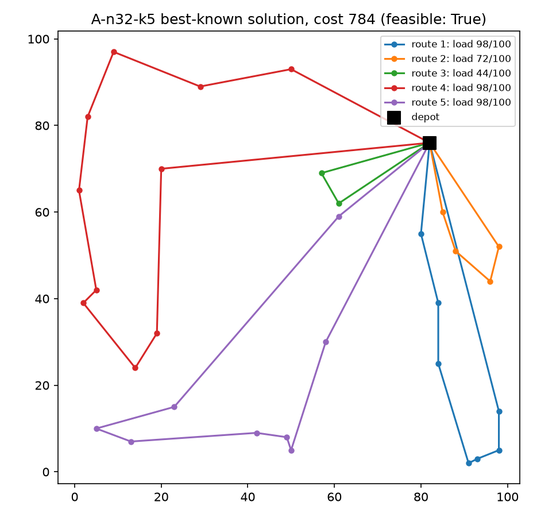

In [1]:
# 0 · Setup: run this cell BEFORE you start recording
import sys, time
from math import factorial
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp

from src.checker import check_solution
from src.data_loader import instance_table, load_bks, load_instance
from src.exact_milp import extract_routes, lp_relaxation_bound, solve_exact


def plot_routes(ax, inst, routes, title):
    """Draw each route in its own colour; the black square is the depot."""
    colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
    xy = inst.coords
    for k, route in enumerate(routes):
        path = [0, *route, 0]
        ax.plot(xy[path, 0], xy[path, 1], "-o", color=colours[k % len(colours)], lw=1.6, ms=5)
    ax.plot(*xy[0], "s", color="black", ms=10)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

## 1 · The problem
A **depot** (the warehouse) serves **customers**. Customer $i$ needs $q_i$ units. Every truck carries at most $Q$ units, and there are $K$ trucks.

| Rule | In words |
|---|---|
| R1 | Every customer is visited exactly once |
| R2 | Every route starts and ends at the depot |
| R3 | The load on a route never exceeds $Q$ |
| R4 | At most $K$ trucks are used |

**Goal:** the shortest total distance. This is the **Capacitated Vehicle Routing Problem (CVRP)**.
With one truck and no capacity limit it becomes the Travelling Salesman Problem, so it is **NP-hard**.

In [2]:
# 1.1 · Why it is hard: the number of possible orders grows like n!
for n in [10, 20, 50]:
    print(f"{n:>3} customers: {factorial(n):.1e} possible orders")

 10 customers: 3.6e+06 possible orders
 20 customers: 2.4e+18 possible orders
 50 customers: 3.0e+64 possible orders


## 2 · The data: CVRPLIB
16 public benchmark instances in three sizes. For every one of them the **best possible cost has been proven**,
so we can measure exactly how far any answer is from the optimum. The data only fills the model with numbers; nothing is trained.

In [3]:
# 2.1 · The 16 instances we use
table = pd.DataFrame(instance_table())[["name", "tier", "customers", "vehicles", "capacity", "bks"]]
table.columns = ["instance", "size", "customers n", "trucks K", "capacity Q", "optimal cost"]
table

,instance,size,customers n,trucks K,capacity Q,optimal cost
0,P-n16-k8,small,15,8,35,450
1,P-n19-k2,small,18,2,160,212
2,P-n20-k2,small,19,2,160,216
3,P-n22-k2,small,21,2,160,216
4,E-n22-k4,small,21,4,6000,375
5,P-n23-k8,small,22,8,40,529
6,B-n31-k5,medium,30,5,100,672
7,A-n32-k5,medium,31,5,100,784
8,A-n37-k5,medium,36,5,100,669
9,P-n40-k5,medium,39,5,140,458


In [4]:
# 2.2 · What one instance file looks like (plain text)
lines = (ROOT / "data" / "raw" / "A-n32-k5.vrp").read_text().splitlines()
print("\n".join(lines[:9]))
print("...")
print("\n".join(lines[39:44]))

NAME : A-n32-k5
COMMENT : (Augerat et al, No of trucks: 5, Optimal value: 784)
TYPE : CVRP
DIMENSION : 32
EDGE_WEIGHT_TYPE : EUC_2D 
CAPACITY : 100
NODE_COORD_SECTION 
 1 82 76
 2 96 44
...
DEMAND_SECTION 
1 0 
2 19 
3 21 
4 6 


In [5]:
# 2.3 · Load an instance and round the distances exactly like CVRPLIB
inst = load_instance("P-n16-k8")
d = np.hypot(*(inst.coords[0] - inst.coords[1]))
print(f"P-n16-k8: {inst.n_customers} customers, capacity Q = {inst.capacity}, trucks K = {inst.max_vehicles}")
print(f"depot -> customer 1: exact {d:.3f}, rounded floor(d + 0.5) = {inst.dist[0, 1]}")

P-n16-k8: 15 customers, capacity Q = 35, trucks K = 8
depot -> customer 1: exact 13.892, rounded floor(d + 0.5) = 14


In [6]:
# 2.4 · Do our distances match CVRPLIB? Check all 16 published optimal solutions
ok = 0
for name in table["instance"]:
    routes, cost = load_bks(name)
    ok += check_solution(load_instance(name), routes, claimed_cost=cost).feasible
print(f"{ok} of {len(table)} published optimal solutions give exactly their published cost")

16 of 16 published optimal solutions give exactly their published cost


## 3 · The maths model (a MILP)
**Decisions**
* $x_{ij} = 1$ if a truck drives straight from $i$ to $j$, otherwise $0$ (binary)
* $u_i$ = load delivered up to customer $i$ (a load counter)

**Goal (1):** $\min \sum_{i \ne j} c_{ij}\, x_{ij}$, the total distance

**Rules**
* (2), (3): $\sum_j x_{ij} = 1$ and $\sum_i x_{ij} = 1$: each customer is left once and entered once
* (4): $\sum_j x_{0j} \le K$: at most $K$ trucks leave the depot
* (5): $\sum_j x_{0j} = \sum_i x_{i0}$: every truck comes back
* (6) **MTZ:** $u_j \ge u_i + q_j - Q\,(1 - x_{ij})$: the load counter grows along a route, so no truck is overloaded and no loop can skip the depot
* (7): $q_i \le u_i \le Q$

Linear rules with a binary $x$ → a **mixed-integer linear program (MILP)**.

## 4 · The model in code (PuLP)
Each cell adds one part of the maths, numbered like the rules above.

In [7]:
# 4.1 · Decisions: x_ij (yes / no) and the load counters u_i, with rule (7) as their bounds
V = range(len(inst.demand))            # all nodes, 0 = depot
N = list(inst.customers)               # customers 1..n
Q, K, q, c = inst.capacity, inst.max_vehicles, inst.demand, inst.dist

prob = pulp.LpProblem("CVRP", pulp.LpMinimize)
arcs = [(i, j) for i in V for j in V if i != j]
x = pulp.LpVariable.dicts("x", arcs, cat="Binary")
u = {i: pulp.LpVariable(f"u_{i}", lowBound=int(q[i]), upBound=Q) for i in N}

In [8]:
# 4.2 · Goal (1): the total distance
prob += pulp.lpSum(int(c[i, j]) * x[i, j] for (i, j) in arcs)

In [9]:
# 4.3 · Rules (2)-(5): visit every customer once, at most K trucks, every truck comes back
for i in N:
    prob += pulp.lpSum(x[i, j] for j in V if j != i) == 1       # (2) leave once
    prob += pulp.lpSum(x[j, i] for j in V if j != i) == 1       # (3) enter once

prob += pulp.lpSum(x[0, j] for j in N) <= K                     # (4) fleet size
prob += pulp.lpSum(x[0, j] for j in N) == pulp.lpSum(x[i, 0] for i in N)   # (5) return

In [10]:
# 4.4 · Rule (6), the MTZ load counter, for every pair of customers
for i in N:
    for j in N:
        if i != j:
            prob += u[j] >= u[i] + int(q[j]) - Q * (1 - x[i, j])

n_bin = sum(v.cat == pulp.LpInteger for v in prob.variables())
print(f"{n_bin} binary variables, {len(prob.variables()) - n_bin} continuous, {len(prob.constraints)} constraints")

240 binary variables, 15 continuous, 242 constraints


## 5 · A stronger model
Two extra **valid** rules: they remove no real plan, only fractional ones.
* (4b) $\sum_j x_{0j} \ge \lceil \sum_i q_i / Q \rceil$: use at least enough trucks for all the demand
* (6′) lifted MTZ: $u_i - u_j + Q\,x_{ij} + (Q - q_i - q_j)\,x_{ji} \le Q - q_j$

They raise the **LP lower bound**, the "no plan can be shorter than this" number.

In [11]:
# 5.1 · LP lower bound of the basic and the stronger model (the optimum is 450)
_, optimum = load_bks("P-n16-k8")
lp_basic, _ = lp_relaxation_bound(inst, strengthened=False)
lp_strong, _ = lp_relaxation_bound(inst, strengthened=True)
print(f"basic model   : no plan shorter than {lp_basic:6.1f}  ({100 * (optimum - lp_basic) / optimum:.0f} % below the optimum)")
print(f"stronger model: no plan shorter than {lp_strong:6.1f}  ({100 * (optimum - lp_strong) / optimum:.0f} % below the optimum)")

gap = pd.read_csv(ROOT / "results" / "exact.csv").groupby("model").root_gap.mean()
print(f"\nAverage over all 12 small and medium instances: {gap['basic']:.0f} % below -> {gap['strengthened']:.0f} % below")

basic model   : no plan shorter than  140.6  (69 % below the optimum)
stronger model: no plan shorter than  395.0  (12 % below the optimum)

Average over all 12 small and medium instances: 48 % below -> 19 % below


## 6 · Solving it: branch-and-bound with HiGHS
1. Solve the **LP relaxation** (a road may be used by a fraction) → a **lower bound**.
2. If some $x_{ij}$ is fractional, **branch**: one sub-problem with $x_{ij} = 0$, one with $x_{ij} = 1$.
3. **Prune** any branch whose bound is not better than the best plan found so far.
4. When the best plan meets the bound, it is **proven optimal**.

**Settings:** time limit 300 s. Costs are whole numbers, so a gap below 1 is already a proof.
We read **HiGHS's own status**, because PuLP's status says "Optimal" even after a time-out.

In [12]:
# 6.1 · Solve with HiGHS (about 20-30 seconds)
solver = pulp.HiGHS(msg=False, timeLimit=300, gapRel=0.0, gapAbs=0.999)
start = time.perf_counter()
prob.solve(solver)
seconds = time.perf_counter() - start

highs = prob.solverModel                       # the HiGHS object itself: its real status
info = highs.getInfo()
print("solver status :", highs.modelStatusToString(highs.getModelStatus()))
print("best cost     :", round(pulp.value(prob.objective)))
print("lower bound   :", round(info.mip_dual_bound, 1))
print("B&B nodes     :", info.mip_node_count)
print(f"time          : {seconds:.1f} s")

solver status : Optimal
best cost     : 450
lower bound   : 450.0
B&B nodes     : 12465
time          : 23.6 s


feasible: True | cost: 450 | published optimum: 450
truck 1: depot -> [1] -> depot   load 19/35
truck 2: depot -> [2] -> depot   load 30/35
truck 3: depot -> [4, 11] -> depot   load 30/35
truck 4: depot -> [5, 9, 3] -> depot   load 35/35
truck 5: depot -> [6] -> depot   load 31/35
truck 6: depot -> [7, 14] -> depot   load 34/35
truck 7: depot -> [8, 13] -> depot   load 34/35
truck 8: depot -> [10, 12, 15] -> depot   load 33/35


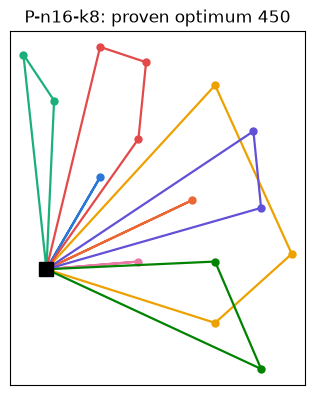

In [13]:
# 6.2 · Rebuild the routes (follow x_ij = 1 from the depot) and check them independently
routes = extract_routes(inst, x)
check = check_solution(inst, routes)
print("feasible:", check.feasible, "| cost:", check.cost, "| published optimum:", optimum)
for k, r in enumerate(routes, 1):
    print(f"truck {k}: depot -> {r} -> depot   load {check.loads[k - 1]}/{Q}")

fig, ax = plt.subplots(figsize=(4.6, 4.6))
plot_routes(ax, inst, routes, f"P-n16-k8: proven optimum {check.cost}")
plt.show()

In [14]:
# 6.3 · The stronger model: same answer, much less work
strong = solve_exact(inst, time_limit=300, strengthened=True)
pd.DataFrame({"model": ["basic", "stronger"],
              "cost": [check.cost, strong.cost],
              "B&B nodes": [info.mip_node_count, strong.nodes],
              "time (s)": [round(seconds, 1), round(strong.runtime, 1)]})

,model,cost,B&B nodes,time (s)
0,basic,450,12465,23.6
1,stronger,450,602,3.0


## 7 · Results on the small instances (300 s limit each)

In [15]:
# 7.1 · All six small instances with both models (experiment E1)
ex = pd.read_csv(ROOT / "results" / "exact.csv")

def show(r):
    tag = "proven" if r.status == "optimal" else "time limit"
    return f"{int(r.cost)} · {tag} · {r.runtime:.0f} s"

rows = []
for name, g in ex[ex.tier == "small"].groupby("instance", sort=False):
    b, s = g[g.model == "basic"].iloc[0], g[g.model == "strengthened"].iloc[0]
    rows.append({"instance": name, "customers": b.n, "basic model": show(b), "stronger model": show(s), "optimum": int(b.bks)})
display(pd.DataFrame(rows).sort_values("customers").reset_index(drop=True))

med = ex[ex.tier == "medium"].groupby("model").gap_to_bks.mean()
print(f"Medium instances (30-50 customers) after 300 s: nothing proven; basic {med['basic']:.2f} % and stronger {med['strengthened']:.2f} % above the optimum")

,instance,customers,basic model,stronger model,optimum
0,P-n16-k8,15,450 · proven · 30 s,450 · proven · 3 s,450
1,P-n19-k2,18,218 · time limit · 300 s,212 · proven · 90 s,212
2,P-n20-k2,19,216 · time limit · 300 s,216 · proven · 49 s,216
3,P-n22-k2,21,216 · time limit · 300 s,216 · proven · 51 s,216
4,E-n22-k4,21,379 · time limit · 300 s,375 · time limit · 300 s,375
5,P-n23-k8,22,545 · time limit · 300 s,565 · time limit · 300 s,529


Medium instances (30-50 customers) after 300 s: nothing proven; basic 13.94 % and stronger 8.05 % above the optimum


## 8 · The exponential wall
The same instance (A-n32-k5), grown from 6 to 25 customers.

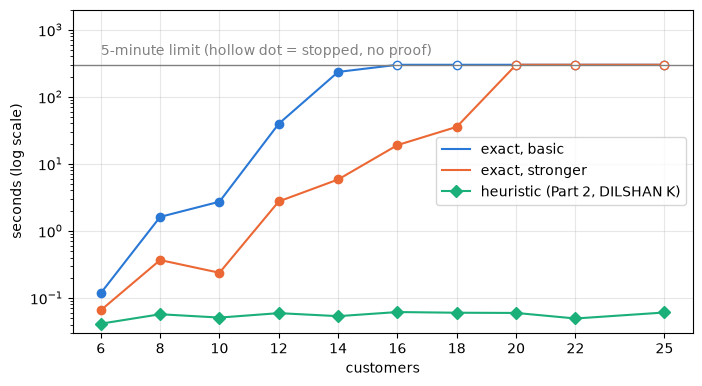

In [16]:
# 8.1 · Runtime as the instance grows (log scale: each grid line is 10 times the one below)
sc = pd.read_csv(ROOT / "results" / "scaling.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
for method, colour, label in [("MILP (basic)", "#2a78d6", "exact, basic"), ("MILP (strengthened)", "#eb6834", "exact, stronger")]:
    g = sc[sc.method == method].sort_values("n")
    proven = g.status == "optimal"
    ax.plot(g.n, g.runtime, "-", color=colour, label=label)
    ax.plot(g.n[proven], g.runtime[proven], "o", color=colour)
    ax.plot(g.n[~proven], g.runtime[~proven], "o", mfc="white", color=colour)
h = sc[sc.method == "Clarke-Wright + SA"].groupby("n").runtime.mean()
ax.plot(h.index, h.values, "D-", color="#1baf7a", label="heuristic (Part 2, DILSHAN K)")
ax.axhline(300, color="grey", lw=1)
ax.text(6, 420, "5-minute limit (hollow dot = stopped, no proof)", color="grey")
ax.set_yscale("log")
ax.set_ylim(0.03, 2000)
ax.set_xticks(sorted(sc.n.unique()))
ax.set_xlabel("customers")
ax.set_ylabel("seconds (log scale)")
ax.grid(alpha=0.3)
ax.legend(loc="center right")
plt.show()

## Part 2 → DILSHAN K (MS26901176): the heuristic
For real-sized problems we need something much faster: savings, local search and simulated annealing.